In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta

from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester

In [2]:
data = DataTimeseries('./Data/nq_continous.csv')
data.resample_data('5min')
data.convert_timezone('America/New_York')

data.slice(start_date=pd.Timestamp(year=2018, month=1, day=1))  # only include data after 2018
IS_data, OOS_data = data.split(split_date=pd.Timestamp(year=2023, month=1, day=1))

df = IS_data.get_ohlc_prices_series()
df


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



,Open,High,Low,Close,Volume
Time,,,,,
2018-01-01 18:05:00-05:00,6407.75,6411.50,6407.75,6411.50,32051.75
2018-01-01 18:10:00-05:00,6412.75,6415.00,6412.50,6412.50,32068.25
2018-01-01 18:15:00-05:00,6413.00,6413.75,6412.00,6412.00,32064.75
2018-01-01 18:20:00-05:00,6413.50,6413.50,6412.50,6413.25,32065.00
2018-01-01 18:25:00-05:00,6413.50,6414.75,6413.50,6414.25,32071.25
...,...,...,...,...,...
2022-12-30 16:40:00-05:00,11048.75,11048.75,11043.75,11043.75,55233.25
2022-12-30 16:45:00-05:00,11043.75,11044.50,11040.50,11040.50,55212.75
2022-12-30 16:50:00-05:00,11039.50,11040.25,11037.75,11037.75,55194.75


In [3]:
df['8ema'] = ta.ema(df['Close'], length=8)
df['32ema'] = ta.ema(df['Close'], length=32)

df['base'] = np.where(df['8ema'] >= df['32ema'], 1, -1)
mask = (df.index.hour >= 7) & (df.index.hour < 12)

# Initialize signal column
df['signal'] = np.nan

# Case 1 — during allowed hours → FOLLOW the system normally
df.loc[mask, 'signal'] = df.loc[mask, 'base']

# Case 2 — outside allowed hours → manage positions:
# If base flips, go FLAT, but do not reverse into new direction.
df['signal'] = df['signal'].combine_first(
    # Outside window:
    # Keep old position UNLESS the base signal flips → then go flat (0)
    df['base'].where(mask, np.nan)
)

# Now forward-fill positions
df['signal'] = df['signal'].ffill()

# Replace initial NaNs with flat
df['signal'] = df['signal'].fillna(0)



        Backtest Results from 2018-01-01 18:05:00-05:00 to 2022-12-30 17:00:00-05:00 (1823 days 22:55:00)
        Equity:     $100,000.00 -> $112,473.50
        Buy & Hold: $100,000.00 -> $72,217.89
        Buy & Hold Return (%): 72.22%
        Strategy Return (%):   12.47%

        Total Trades:     3972.00
        Win Rate:         32.30%
        95% CI:           30.86% - 33.77%
        Avg. Win:         $159.39
        Avg. Loss:        $-71.97
        Ratio Win/Loss:   2.21
        Expected Value:   $2.76

        Largest Win:      $1,680.50
        Largest Loss:     $-1,195.50
        Max Consec. Wins: 2
        Max Consec. Loss: 2

        Max Drawdown from 2021-07-27 13:25:00-04:00 to 2022-01-28 10:45:00-05:00 (184 days 22:20:00)
        Max Drawdown:     $-8,548.00
        Max Drawdown (%): -7.55%

        Slippage:   0 ticks
        Commission: $0.00
        Contract Multiplier: $2.00

        Performance Metrics:
        CAGR:              2.38%
        Sharpe Ratio:      0

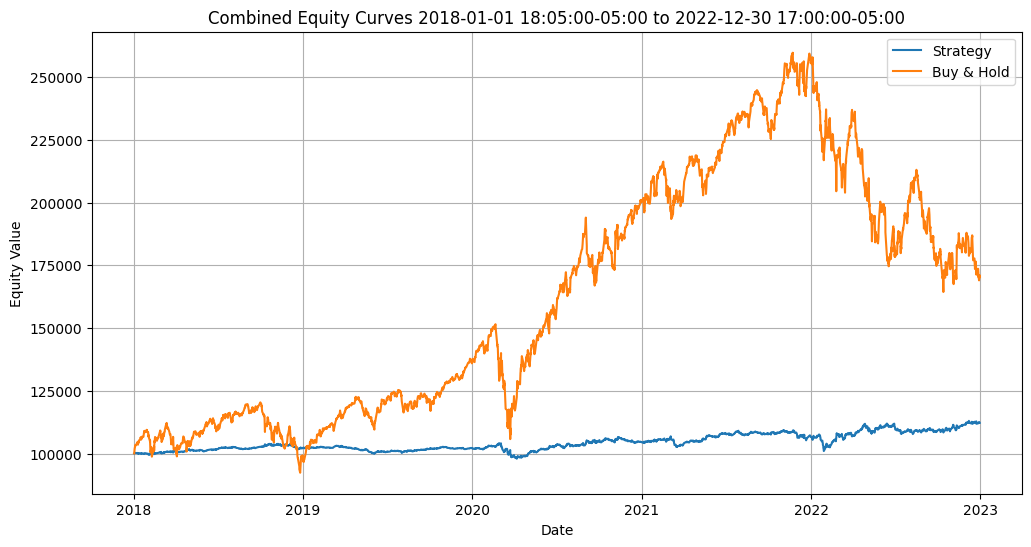

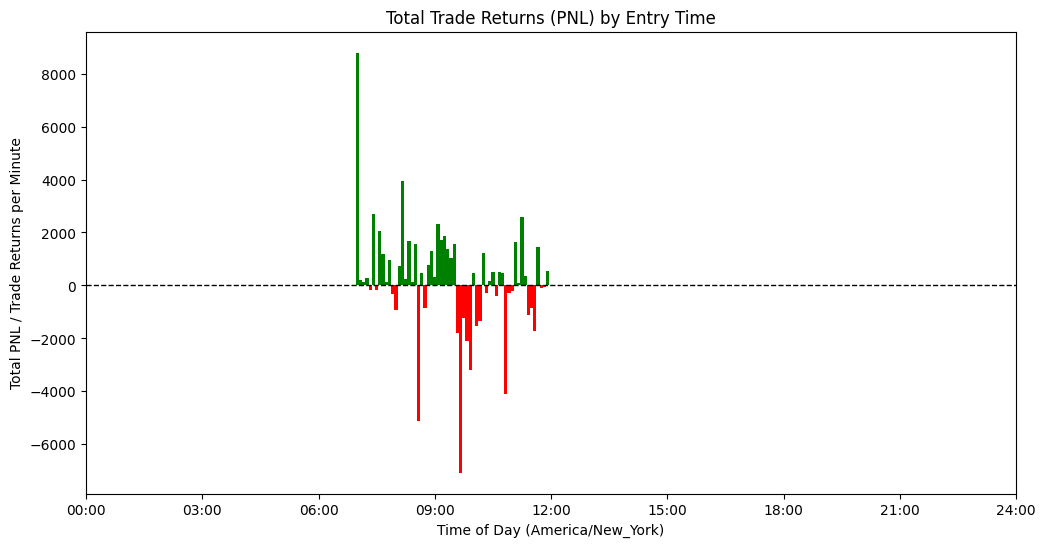

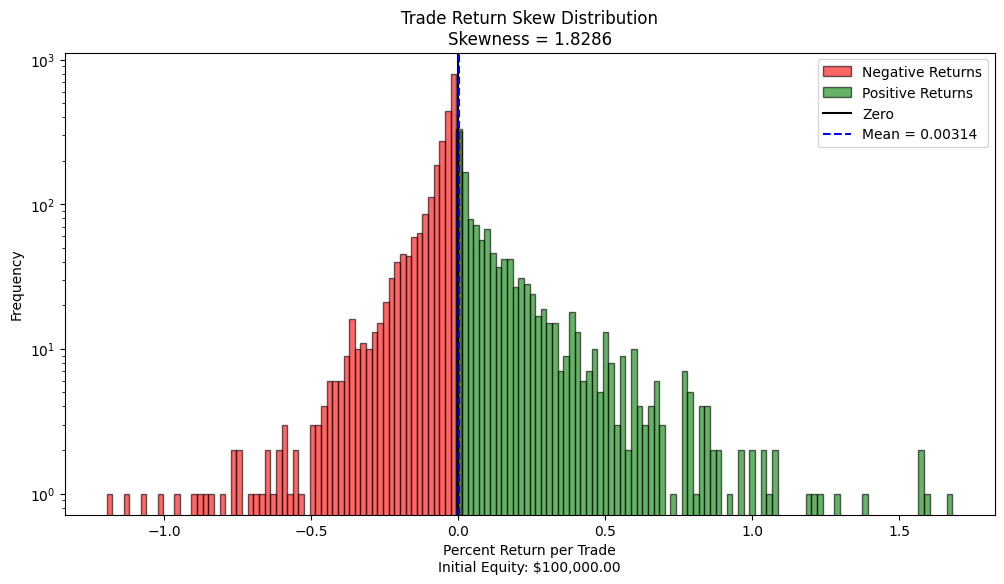

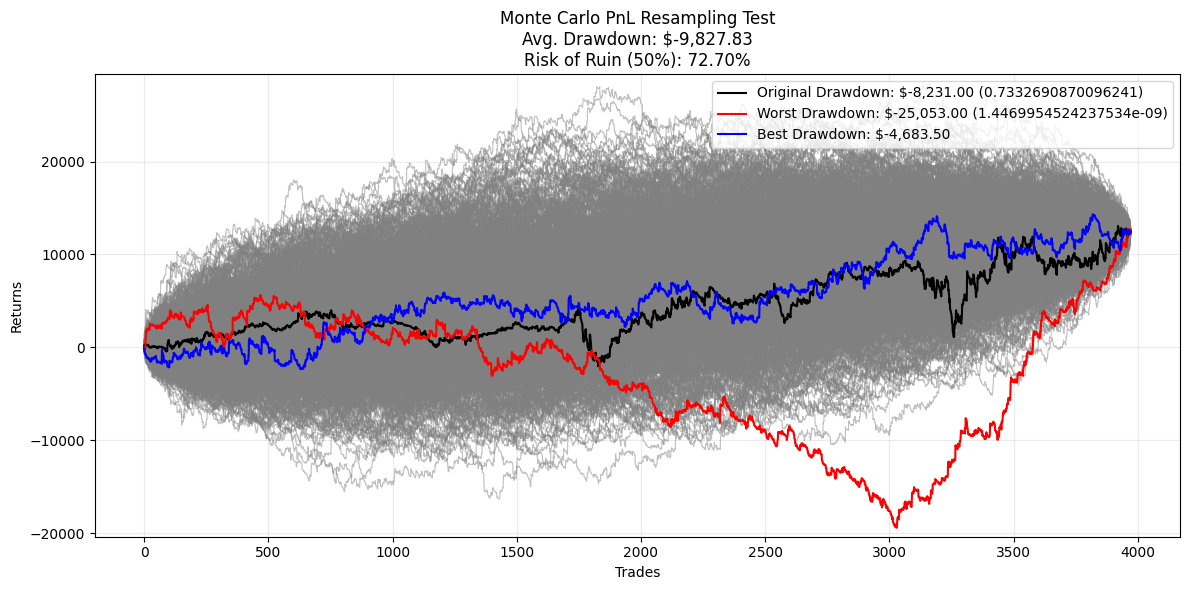

In [5]:
from Engine.EquityCurve import EquityCurve


bt = Backtester(
    IS_data.get_ohlc_prices(),
    IS_data.get_indicies(),
    df['signal'],
    IS_data.get_timeframe(),
    tick_value=0.5,
    contract_multiplier=2,
    slippage_ticks=0,
    commission=0
)
bt.full_backtest()
print(bt)

equity_curve = bt.generate_equity_curve()
bh_curve = bt.generate_buy_hold_equity_curve()
EquityCurve.combine_equity_curves([equity_curve, bh_curve], ['Strategy', 'Buy & Hold'])

bt.generate_trade_time_distribution()
bt.generate_skew_curve().plot()
bt.monte_carlo_pnl_resampling_test(iterations=1000, pct_of_trades=1)